<a href="https://query.farm/"><img src="assets/query-farm-strata-sun.svg" alt="Query.Farm — Strata Sun" width="252"></a>

<a href="https://query.farm/vgi/"><img src="assets/vgi-logo.png" alt="VGI" width="280"></a>

[Query.Farm](https://query.farm/) · [VGI](https://query.farm/vgi/) · [Setup and provenance](README.md)

# 01 · A resolved frame still needs context

**Does a non-NULL source-map lookup mean the frame is close to a mapping?**
We will decode an authored JavaScript source map, resolve fifteen synthetic stack
frames in SQL, and inspect the generated-coordinate distance to the preceding token.
The worker's raw resolution stays separate from a deliberately simple reporting
policy: retain only mappings on the same generated line and within a column gap.

All inputs are synthetic and local. We are counting stack-frame rows, not exceptions,
users, or affected sessions. A small gap is not a confidence score or proof that the
correct deployment map was supplied. In real telemetry, match the map to the exact
build and verify the producer's line/column conventions before interpreting results.

## Choose a reporting gap

`MAX_COLUMN_GAP=4` includes a raw match only when its token is on the same generated
line and at most four columns behind the frame. The experiment changes this to 10.
This is an illustrative screening rule, not a source-map validity rule. Wider gaps
may be legitimate because mappings need not exist at every generated column.
Restart the kernel and run all after changing this nonnegative integer.

In [1]:
MAX_COLUMN_GAP = 4

In [2]:
import os

os.environ["PLOOMBER_STATS_ENABLED"] = "false"
import haybarn
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator, ScalarFormatter
from notebook_support import finish, prose, theme

if type(MAX_COLUMN_GAP) is not int or MAX_COLUMN_GAP < 0:
    raise ValueError("MAX_COLUMN_GAP must be a nonnegative integer.")
gaps = counts = checks = summary = pd.DataFrame()
theme()
con = haybarn.connect()
%load_ext sql
%config SqlMagic.autopandas = True
%config SqlMagic.feedback = False
%config SqlMagic.displaycon = False
%sql con
%matplotlib inline

/Users/rusty/Development/notebook-rollout/full-rollout/checkouts/vgi-sourcemap/notebooks/.venv/lib/python3.14/site-packages/sql/parse.py:339: SyntaxWarning: "\:" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\:"? A raw string is also an option.
  Given a query, replaces all occurrences of ':variable' with '\:variable' and
/Users/rusty/Development/notebook-rollout/full-rollout/checkouts/vgi-sourcemap/notebooks/.venv/lib/python3.14/site-packages/sql/parse.py:369: SyntaxWarning: "\:" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\:"? A raw string is also an option.
  Given a query, replaces all occurrences of 'example'[x:y] with 'example'[x\:y].


Tip: You may define configurations in /Users/rusty/Development/notebook-rollout/full-rollout/checkouts/vgi-sourcemap/notebooks/pyproject.toml or /Users/rusty/.jupysql/config.

Did not find user configurations in /Users/rusty/Development/notebook-rollout/full-rollout/checkouts/vgi-sourcemap/notebooks/pyproject.toml.

## Attach the pinned native release

The literal location downloads and checks the platform's v0.4.0 release, then caches
it. No Rust installation or worker checkout is needed for this notebook. The worker
reads the map supplied below; it does not fetch a `sourceMappingURL` or contact a
symbol server. All returned coordinates are zero based.

In [3]:
%%sql
INSTALL vgi FROM community;
LOAD vgi;
ATTACH 'sourcemap' (TYPE vgi, LOCATION 'github-auto://Query-farm/vgi-sourcemap@v0.4.0');

,Success


## Inspect the map before interpreting its results

This small map has five authored tokens across two generated lines and two source
files. The JSON wrapper contains compressed Base64-VLQ mappings; `tokens()` decodes
them into usable rows. `sourceRoot=/src` is already incorporated into returned paths.
`sourcesContent` contains short original snippets, independent of our frame policy.

The map's `file` field is a label, not a content checksum. The fixture is associated
with one authored build; this example does not verify a deployed bundle against it.
Whole-map functions such as `tokens()` fail on an unreadable or malformed map, which
is useful here: a failed map load must not masquerade as a successful empty result.

In [4]:
%%sql
CREATE TABLE map_tokens AS
SELECT * FROM sourcemap.main.tokens('fixtures/app.min.js.map');
CREATE TABLE map_sources AS
SELECT * FROM sourcemap.main.sources('fixtures/app.min.js.map');
SELECT * FROM sourcemap.main.meta('fixtures/app.min.js.map');
SELECT gen_line,gen_col,source,src_line,src_col,name FROM map_tokens
ORDER BY gen_line,gen_col;

,gen_line,gen_col,source,src_line,src_col,name
0,0,2,/src/checkout.js,0,0,checkout
1,0,10,/src/checkout.js,1,2,validate
2,0,22,/src/price.js,0,0,price
3,1,4,/src/price.js,1,2,round
4,1,18,/src/checkout.js,2,2,submit


## Normalize the fixture's explicitly one-based coordinates

Every valid input below uses **one-based lines and one-based columns** by definition
of this fixture. Subtract one from both before calling the worker. Real stack-trace
formats vary; do not apply this conversion without checking your data source.

The examples include exact tokens, nearby and distant positions, positions on a
later line, a missing line, and an invalid zero line. Keep the input contract separate
from whether the parser returns a location. IDs identify frames and remain stable.

In [5]:
%%sql
CREATE TABLE frames AS
SELECT * FROM (VALUES
 ('F01',1,1,'Before the first mapping'),
 ('F02',1,3,'Exact first token'),
 ('F03',1,7,'Four columns after first token'),
 ('F04',1,10,'Seven columns after first token'),
 ('F05',1,11,'Exact second token'),
 ('F06',1,22,'Eleven columns after second token'),
 ('F07',1,23,'Exact third token'),
 ('F08',1,101,'Far past final token on line one'),
 ('F09',2,1,'Before first token on line two'),
 ('F10',2,5,'Exact first token on line two'),
 ('F11',2,13,'Eight columns after preceding token'),
 ('F12',2,19,'Exact last token'),
 ('F13',10,1,'Beyond all mapped lines'),
 ('F14',NULL,3,'Missing line'),
 ('F15',0,1,'Invalid one-based line')
) t(frame_id,reported_line,reported_column,fixture_note);
CREATE TABLE normalized AS
SELECT *,coalesce(reported_line>=1 AND reported_column>=1,false) AS input_valid,
 CASE WHEN reported_line>=1 AND reported_column>=1 THEN reported_line-1 END AS gen_line,
 CASE WHEN reported_line>=1 AND reported_column>=1 THEN reported_column-1 END AS gen_col
FROM frames;
SELECT * FROM normalized ORDER BY frame_id;

,frame_id,reported_line,reported_column,fixture_note,input_valid,gen_line,gen_col
0,F01,1,1,Before the first mapping,True,0,0
1,F02,1,3,Exact first token,True,0,2
2,F03,1,7,Four columns after first token,True,0,6
3,F04,1,10,Seven columns after first token,True,0,9
4,F05,1,11,Exact second token,True,0,10
5,F06,1,22,Eleven columns after second token,True,0,21
6,F07,1,23,Exact third token,True,0,22
7,F08,1,101,Far past final token on line one,True,0,100
8,F09,2,1,Before first token on line two,True,1,0
9,F10,2,5,Exact first token on line two,True,1,4


## Resolve valid frames in bulk and retain every input row

`lookup_all` takes a relation and passes the frame ID through. We materialize the
worker result once, then left join it to the complete input table. Invalid inputs
remain visible, even though we do not submit them for resolution.

The worker chooses the greatest token position less than or equal to the requested
position. This can be a token on an earlier generated line. A successful lookup also
does not interpolate original line/column values: it returns the token's stored
original location. We add one only for the human-facing source location below.

In [6]:
%%sql
CREATE TABLE raw_resolutions AS
SELECT * FROM sourcemap.main.lookup_all(
 (SELECT frame_id,gen_line,gen_col FROM normalized WHERE input_valid),
 map := 'fixtures/app.min.js.map',id := 'frame_id',line := 'gen_line',col := 'gen_col');
CREATE TABLE resolved_frames AS
SELECT n.*,r.source,r.src_line,r.src_col,r.name
FROM normalized n LEFT JOIN raw_resolutions r USING(frame_id);
SELECT frame_id,input_valid,gen_line,gen_col,source,
 src_line+1 AS source_line_one_based,src_col+1 AS source_column_one_based,name
FROM resolved_frames ORDER BY frame_id;

,frame_id,input_valid,gen_line,gen_col,source,source_line_one_based,source_column_one_based,name
0,F01,True,0,0,None,<NA>,<NA>,None
1,F02,True,0,2,/src/checkout.js,1,1,checkout
2,F03,True,0,6,/src/checkout.js,1,1,checkout
3,F04,True,0,9,/src/checkout.js,1,1,checkout
4,F05,True,0,10,/src/checkout.js,2,3,validate
5,F06,True,0,21,/src/checkout.js,2,3,validate
6,F07,True,0,22,/src/price.js,1,1,price
7,F08,True,0,100,/src/price.js,1,1,price
8,F09,True,1,0,/src/price.js,1,1,price
9,F10,True,1,4,/src/price.js,2,3,round


## Locate the preceding token and apply an explicit screen

The SQL lateral join exposes the token's generated coordinates, which `lookup_all`
does not return. It is an audit of the worker's precedence rule, checked against the
actual returned source location. We measure a column gap **only on the same line**;
subtracting columns across different lines would not describe a useful distance.

Missing source resolution, invalid input, cross-line matches and large same-line gaps
remain distinct. None is silently converted to a zero gap. Excluding a result from
this reporting view does not make the underlying mapping incorrect.

In [7]:
%%sql
CREATE TABLE match_audit AS
SELECT r.*,t.gen_line AS token_gen_line,t.gen_col AS token_gen_col,
 t.source AS token_source,t.src_line AS token_src_line,t.src_col AS token_src_col,
 CASE WHEN r.gen_line=t.gen_line THEN r.gen_col-t.gen_col END AS column_gap
FROM resolved_frames r LEFT JOIN LATERAL (
 SELECT * FROM map_tokens t WHERE r.input_valid AND
 (t.gen_line<r.gen_line OR (t.gen_line=r.gen_line AND t.gen_col<=r.gen_col))
 ORDER BY t.gen_line DESC,t.gen_col DESC LIMIT 1
) t ON true;
CREATE TABLE audited_frames AS
SELECT *,CASE
 WHEN NOT input_valid THEN 'Invalid input coordinates'
 WHEN source IS NULL THEN 'No source resolution'
 WHEN gen_line<>token_gen_line THEN 'Token on an earlier line'
 WHEN column_gap>{{ MAX_COLUMN_GAP }} THEN 'Same line; gap exceeds policy'
 ELSE 'Included by policy' END AS review_state
FROM match_audit;
SELECT frame_id,gen_line,gen_col,token_gen_line,token_gen_col,column_gap,review_state
FROM audited_frames ORDER BY frame_id;

,frame_id,gen_line,gen_col,token_gen_line,token_gen_col,column_gap,review_state
0,F01,0,0,<NA>,<NA>,<NA>,No source resolution
1,F02,0,2,0,2,0,Included by policy
2,F03,0,6,0,2,4,Included by policy
3,F04,0,9,0,2,7,Same line; gap exceeds policy
4,F05,0,10,0,10,0,Included by policy
5,F06,0,21,0,10,11,Same line; gap exceeds policy
6,F07,0,22,0,22,0,Included by policy
7,F08,0,100,0,22,78,Same line; gap exceeds policy
8,F09,1,0,0,22,<NA>,Token on an earlier line
9,F10,1,4,1,4,0,Included by policy


In [8]:
%%sql gaps <<
SELECT frame_id,column_gap,source,review_state FROM audited_frames
WHERE column_gap IS NOT NULL ORDER BY column_gap,frame_id;

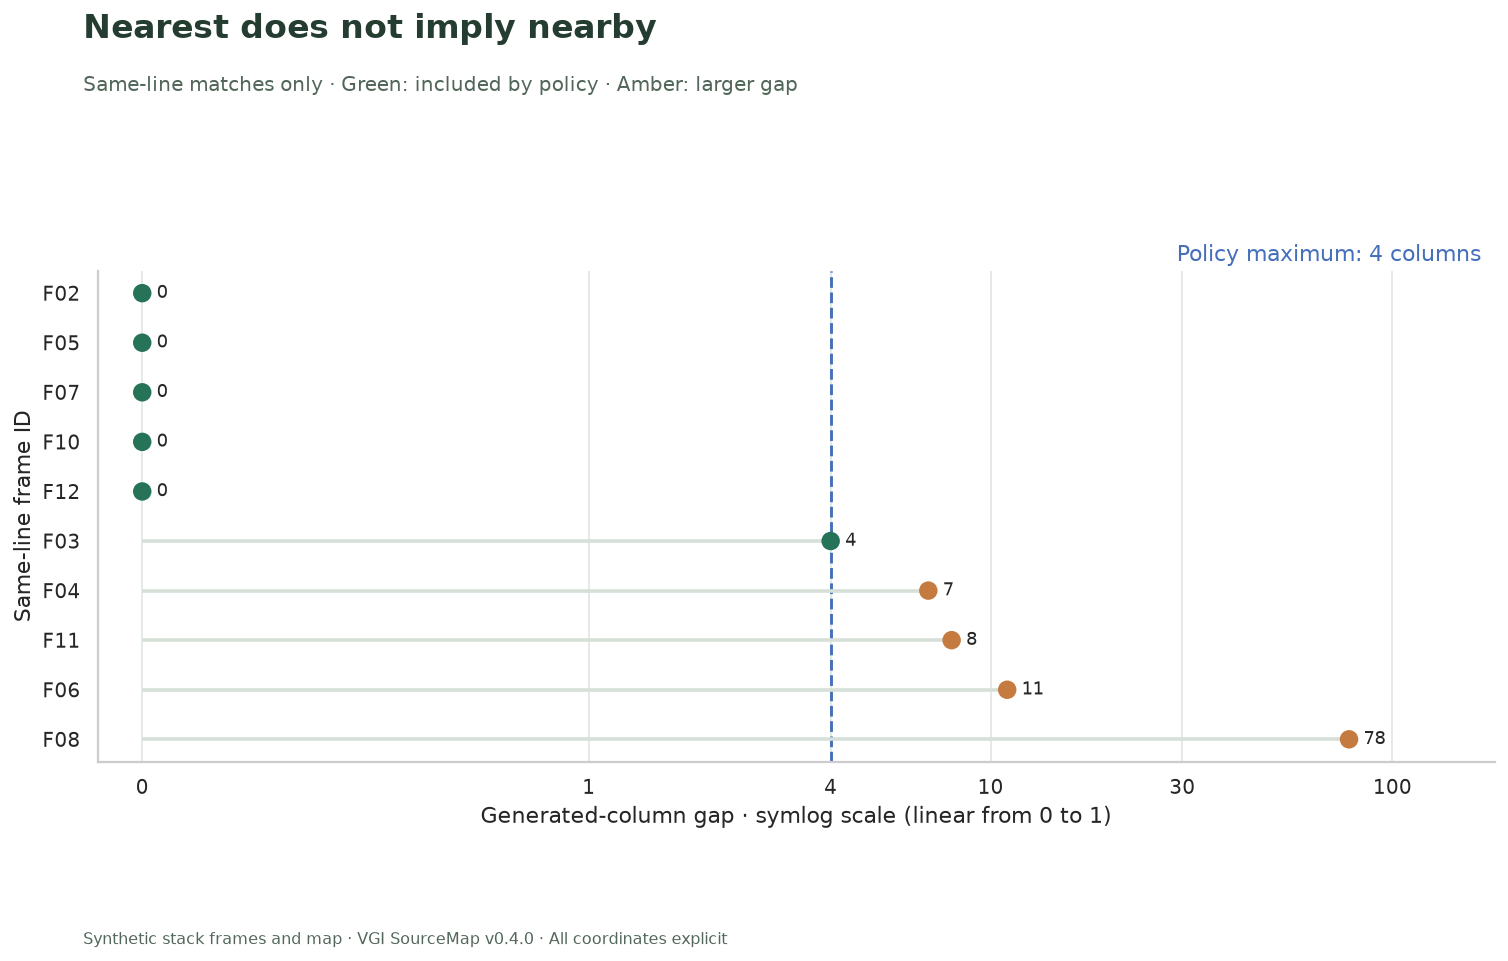

**10 frames** have same-line source matches; their gaps range from **0 to 78 generated columns**. Exact tokens have zero gap. The axis includes the distant frame with a labeled nonlinear scale. Cross-line, unresolved and invalid frames remain in the full accounting below.

In [9]:
fig, ax = plt.subplots(figsize=(12, 7.5))
colors = ["#267358" if s == "Included by policy" else "#c57b40" for s in gaps.review_state]
ax.hlines(range(len(gaps)), 0, gaps.column_gap, color="#d6dfd8", linewidth=2)
ax.scatter(gaps.column_gap, range(len(gaps)), c=colors, s=85, zorder=3)
for y, gap in enumerate(gaps.column_gap):
    ax.annotate(
        str(int(gap)),
        (gap, y),
        xytext=(8, 0),
        textcoords="offset points",
        va="center",
        fontsize=10,
        bbox={"facecolor": "white", "edgecolor": "none", "pad": 1},
    )
ax.set_yticks(range(len(gaps)), gaps.frame_id)
ax.invert_yaxis()
ax.set_xscale("symlog", linthresh=1)
ax.set_xticks([0, 1, 4, 10, 30, 100])
ax.xaxis.set_major_formatter(ScalarFormatter())
ax.set_xlim(-0.1, 180)
ax.axvline(MAX_COLUMN_GAP, color="#456fba", linestyle="--", linewidth=1.6, zorder=1)
ax.text(
    0.99,
    1.02,
    f"Policy maximum: {MAX_COLUMN_GAP} columns",
    transform=ax.transAxes,
    ha="right",
    color="#456fba",
)
ax.set_xlabel("Generated-column gap · symlog scale (linear from 0 to 1)")
ax.set_ylabel("Same-line frame ID")
ax.grid(axis="y", visible=False)
finish(
    fig,
    "Nearest does not imply nearby",
    "Same-line matches only · Green: included by policy · Amber: larger gap",
    "01_mapping_gaps.png",
    bottom=0.12,
)
prose(
    f"**{len(gaps)} frames** have same-line source matches; their gaps range from "
    f"**{int(gaps.column_gap.min())} to {int(gaps.column_gap.max())} generated columns**. "
    "Exact tokens have zero gap. The axis includes the distant frame with a labeled nonlinear scale. "
    "Cross-line, unresolved and invalid frames remain in the full accounting below."
)

## Reconcile the complete frame population

Every input frame appears exactly once. The first chart intentionally shows only
same-line gaps; this chart restores the full denominator. The policy changes which
raw resolutions enter a reporting view, while the map and raw worker results stay fixed.

In [10]:
%%sql counts <<
WITH states(state,sort_order) AS (VALUES
 ('Included by policy',1),('Same line; gap exceeds policy',2),
 ('Token on an earlier line',3),('No source resolution',4),('Invalid input coordinates',5))
SELECT state,count(frame_id) AS frames FROM states
LEFT JOIN audited_frames ON review_state=state GROUP BY state,sort_order ORDER BY sort_order;

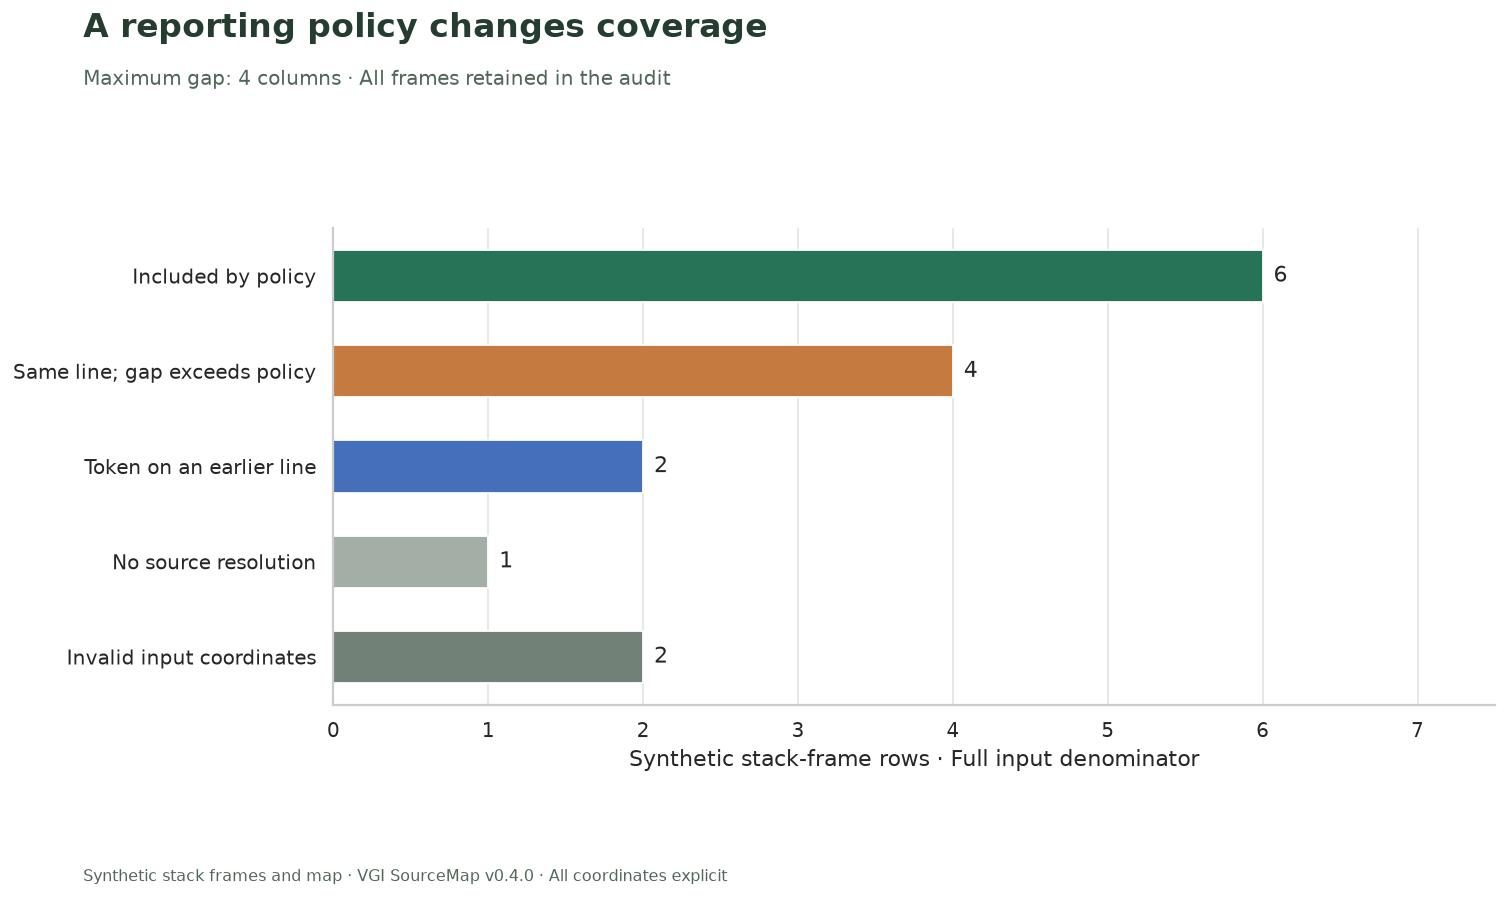

The worker returns source locations for **12 of 15 input frames**; the illustrative reporting policy includes **6 of 15 (40.0%)**. The other categories remain part of the denominator. These are coverage measures, not mapping accuracy.

In [11]:
fig, ax = plt.subplots(figsize=(12, 7))
bars = ax.barh(
    counts.state,
    counts.frames,
    color=["#267358", "#c57b40", "#456fba", "#a3aea6", "#718177"],
    height=0.55,
)
ax.bar_label(bars, padding=6, fontsize=12)
ax.invert_yaxis()
ax.set_xlim(0, max(1, int(counts.frames.max())) * 1.25)
ax.xaxis.set_major_locator(MaxNLocator(integer=True))
ax.set_xlabel("Synthetic stack-frame rows · Full input denominator")
ax.grid(axis="y", visible=False)
finish(
    fig,
    "A reporting policy changes coverage",
    f"Maximum gap: {MAX_COLUMN_GAP} columns · All frames retained in the audit",
    "02_frame_accounting.png",
    bottom=0.12,
)
included = int(counts.loc[counts.state == "Included by policy", "frames"].iloc[0])
total = int(counts.frames.sum())
raw_count = con.execute("SELECT count(*) FROM raw_resolutions WHERE source IS NOT NULL").fetchone()[
    0
]
prose(
    f"The worker returns source locations for **{raw_count} of {total} input frames**; "
    f"the illustrative reporting policy includes **{included} of {total} ({100 * included / total:.1f}%)**. "
    "The other categories remain part of the denominator. These are coverage measures, not mapping accuracy."
)

## Show original code without inventing it

Join the resolved source path to `sources()` and retrieve the embedded source text.
Only the human-facing line/column display adds one. A real map may omit
`sourcesContent`; retain that absence instead of substituting generated code.

In [12]:
%%sql
CREATE TABLE original_content AS
SELECT *,sourcemap.main.source_content('fixtures/app.min.js.map',src_id) AS source_text
FROM map_sources;
SELECT a.frame_id,a.source,a.src_line+1 AS source_line_one_based,
 a.src_col+1 AS source_column_one_based,a.name,
 trim(string_split(c.source_text,chr(10))[a.src_line+1]) AS original_line
FROM audited_frames a LEFT JOIN original_content c ON a.source=c.source
WHERE a.review_state='Included by policy' ORDER BY a.frame_id;

,frame_id,source,source_line_one_based,source_column_one_based,name,original_line
0,F02,/src/checkout.js,1,1,checkout,function checkout(cart) {
1,F03,/src/checkout.js,1,1,checkout,function checkout(cart) {
2,F05,/src/checkout.js,2,3,validate,validate(cart);
3,F07,/src/price.js,1,1,price,function price(item) {
4,F10,/src/price.js,2,3,round,return round(item.total);
5,F12,/src/checkout.js,3,3,submit,return submit(cart);


## A NULL per-row result does not explain its cause

Unlike whole-map table functions, scalar resolution tolerates malformed maps and
missing input. Here an invalid JSON map, a missing map and a position before the first
token all return NULL. Keep map provenance and input validation alongside resolution
so these causes cannot be confused. A missing source can also mean an unmapped token
in other maps; this fixture's five tokens all carry source information.

In [13]:
%%sql
CREATE TABLE null_examples AS
SELECT 'Malformed inline JSON' AS cause,sourcemap.main.lookup('{"broken":',0,2) AS resolved
UNION ALL SELECT 'Missing map',sourcemap.main.lookup(NULL,0,2)
UNION ALL SELECT 'Position before first token',sourcemap.main.lookup('fixtures/app.min.js.map',0,0);
SELECT * FROM null_examples;

,cause,resolved
0,Malformed inline JSON,<NA>
1,Missing map,<NA>
2,Position before first token,<NA>


## Check the map, lookup semantics and full accounting

The fixture's expected token coordinates are independent authored values. The checks
compare the SQL precedence audit with the actual worker output, preserve IDs, and
keep invalid or cross-line positions out of the selected reporting view.

In [14]:
%%sql checks <<
WITH expected(gen_line,gen_col,src_id,src_line,src_col) AS
 (VALUES(0,2,0,0,0),(0,10,0,1,2),(0,22,1,0,0),(1,4,1,1,2),(1,18,0,2,2))
SELECT 'Decoded tokens match the authored coordinates' AS check_name,
 NOT EXISTS((SELECT * FROM expected EXCEPT SELECT gen_line,gen_col,src_id,src_line,src_col FROM map_tokens)
 UNION ALL (SELECT gen_line,gen_col,src_id,src_line,src_col FROM map_tokens EXCEPT SELECT * FROM expected)) AS passed
UNION ALL SELECT 'Bulk result preserves every submitted ID exactly once',
 (SELECT count(*) FROM raw_resolutions)=(SELECT count(*) FROM normalized WHERE input_valid)
 AND (SELECT count(DISTINCT frame_id) FROM raw_resolutions)=(SELECT count(*) FROM raw_resolutions)
UNION ALL SELECT 'Left join preserves every input frame once',
 (SELECT count(*) FROM audited_frames)=(SELECT count(*) FROM frames)
 AND (SELECT count(DISTINCT frame_id) FROM audited_frames)=(SELECT count(*) FROM frames)
UNION ALL SELECT 'One-based fixture coordinates normalized explicitly',
 NOT EXISTS(SELECT 1 FROM normalized WHERE input_valid AND (gen_line<>reported_line-1 OR gen_col<>reported_column-1))
UNION ALL SELECT 'SQL preceding token agrees with raw worker source coordinates',
 NOT EXISTS(SELECT 1 FROM match_audit WHERE source IS DISTINCT FROM token_source
 OR src_line IS DISTINCT FROM token_src_line OR src_col IS DISTINCT FROM token_src_col)
UNION ALL SELECT 'Same-line gaps are nonnegative and cross-line gaps are NULL',
 NOT EXISTS(SELECT 1 FROM match_audit WHERE column_gap<0 OR (gen_line<>token_gen_line AND column_gap IS NOT NULL))
UNION ALL SELECT 'Selected rows satisfy the declared reporting policy',
 NOT EXISTS(SELECT 1 FROM audited_frames WHERE review_state='Included by policy'
 AND (NOT input_valid OR source IS NULL OR gen_line<>token_gen_line OR column_gap>{{ MAX_COLUMN_GAP }}))
UNION ALL SELECT 'Invalid inputs are retained separately',
 (SELECT count(*) FROM audited_frames WHERE review_state='Invalid input coordinates')=(SELECT count(*) FROM normalized WHERE NOT input_valid)
UNION ALL SELECT 'F01 precedes the first token and has no resolution',
 (SELECT source IS NULL AND token_gen_line IS NULL FROM audited_frames WHERE frame_id='F01')
UNION ALL SELECT 'F13 resolves across lines but remains excluded',
 (SELECT source IS NOT NULL AND review_state='Token on an earlier line' FROM audited_frames WHERE frame_id='F13')
UNION ALL SELECT 'Different failure causes return NULL in tolerant resolution',
 (SELECT count(*)=3 AND count(resolved)=0 FROM null_examples)
UNION ALL SELECT 'Both authored source files have embedded content',
 (SELECT count(*)=2 AND bool_and(has_content AND source_text IS NOT NULL) FROM original_content);

In [15]:
assert checks.passed.all(), checks.loc[~checks.passed].to_dict("records")
assert int(counts.frames.sum()) == con.execute("SELECT count(*) FROM frames").fetchone()[0]
assert (
    len(gaps)
    == con.execute("SELECT count(*) FROM audited_frames WHERE column_gap IS NOT NULL").fetchone()[0]
)
prose(
    f"**{len(checks)} SQL checks and both chart population reconciliations passed.** Raw resolution remains separate from the policy decision."
)

**12 SQL checks and both chart population reconciliations passed.** Raw resolution remains separate from the policy decision.

## Experiment · allow a larger same-line gap

Change only `MAX_COLUMN_GAP` from **4 to 10**, restart, and run all. Predict which
frame IDs change category using the gap chart, then check the included source lines.
The decoded tokens, raw lookup results, invalid inputs and cross-line matches should
stay fixed. A larger reported population is not evidence that resolution improved.

For a production analysis, examine build/map association, coordinate conventions and
mapping sparsity before choosing a reporting rule. Reset `MAX_COLUMN_GAP=4` for the
saved default.

In [16]:
con.close()
plt.close("all")

<a href="https://query.farm/"><img src="assets/query-farm-strata-sun.svg" alt="Query.Farm — Strata Sun" width="252"></a>

[Query.Farm](https://query.farm/) · [VGI](https://query.farm/vgi/)